# Week 1 Tutorial: Task 2 (Dataset Audit) and Task 3 (Exploratory Analysis and Baseline)

**Name:** Amogelang Maforaga | **Student ID:** Fbda23-021

**Problem:** Customer churn prediction for a retail bank (Botswana application). The dataset is a Kaggle bank churn dataset, so I am treating this as a general retail bank problem with Botswana as the intended application.

In [1]:
import sys
sys.path.append('..')   # lets the notebook import reusable code from the src/ folder

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score)

from src.churn_utils import (load_data, split_data, threshold_table, FEATURES, TARGET,
                             SENSITIVE_COLS, RANDOM_STATE, PROCESSED_PATH, RAW_SHA256, RAW_PATH)
import hashlib

# Data version check: confirm the raw file is the original, unmodified Kaggle file
actual = hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()
print('Raw data matches expected version (v1):', actual == RAW_SHA256)

df = load_data()
print(df.shape)
df.head()

Raw data matches expected version (v1): True


(115640, 22)


,Surname,First Name,Date of Birth,Gender,Marital Status,Number of Dependents,Occupation,Income,Education Level,Address,...,Preferred Communication Channel,Credit Score,Credit History Length,Outstanding Loans,Churn Flag,Churn Reason,Balance,NumOfProducts,NumComplaints,zip_code
0,Smith,Troy,1987-08-29,Male,Divorced,3,Information systems manager,77710.14,High School,"Diaz Viaduct\nNorth Jessicaville, VI",...,Phone,397,24,41959.74,0,No Reason,211359.05,1,0,26644
1,Sullivan,Katrina,2000-02-07,Female,Married,1,Charity fundraiser,58209.87,High School,"5642 Rachel Pass Suite 320\nPort Peggy, RI",...,Email,665,10,8916.67,0,No Reason,30624.76,4,1,75805
2,Fuller,Henry,1954-02-03,Female,Single,1,Television production assistant,9794.01,High School,"Brittany Flats Apt. 543\nNew Amandaborough, MH",...,Email,715,21,43270.54,0,No Reason,111956.61,2,6,25
3,Young,Antonio,1991-01-15,Female,Divorced,5,Agricultural engineer,15088.98,High School,Unit 3386 Box 0088\nDPO AE,...,Phone,747,17,17887.65,0,No Reason,201187.61,1,0,71940
4,Andersen,John,1992-04-08,Female,Divorced,2,"Teacher, early years/pre",60726.56,Master's,"0120 Leslie River\nWest Lindseychester, MN",...,Email,549,25,32686.84,0,No Reason,60391.24,5,6,98290


## Task 2: Dataset Audit

### 2.1 Structure and completeness

In [2]:
df.info()
print()
print('Missing values per column:')
print(df.isnull().sum())
print()
print('Duplicate rows:', df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 115640 entries, 0 to 115639
Data columns (total 22 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   Surname                          115640 non-null  str    
 1   First Name                       115640 non-null  str    
 2   Date of Birth                    115640 non-null  str    
 3   Gender                           115640 non-null  str    
 4   Marital Status                   115640 non-null  str    
 5   Number of Dependents             115640 non-null  int64  
 6   Occupation                       115640 non-null  str    
 7   Income                           115640 non-null  float64
 8   Education Level                  115640 non-null  str    
 9   Address                          115640 non-null  str    
 10  Customer Tenure                  115640 non-null  int64  
 11  Customer Segment                 115640 non-null  str    
 12  Preferred Com

Duplicate rows: 0


**Finding:** There are no missing values and no duplicate rows across all 115,640 rows and 22 columns. This is unusually clean for real-world data, which I come back to under provenance.

### 2.2 Class balance of the target (Churn Flag)

Churn Flag
0    101546
1     14094
Name: count, dtype: int64



Churn Flag
0    87.81%
1    12.19%
Name: count, dtype: str


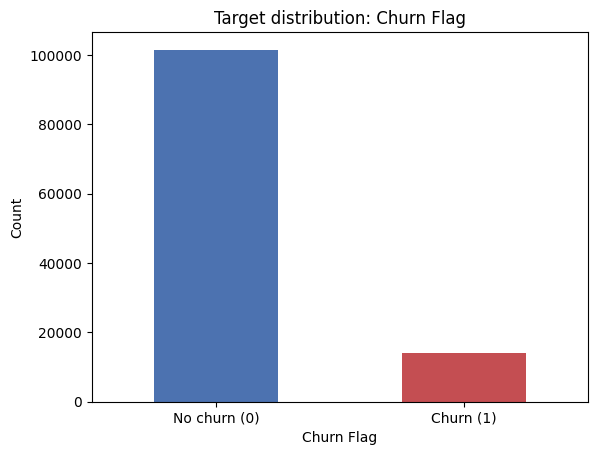

In [3]:
counts = df['Churn Flag'].value_counts()
print(counts)
print()
print((counts / len(df) * 100).round(2).astype(str) + '%')

counts.sort_index().plot(kind='bar', color=['#4C72B0', '#C44E52'])
plt.xticks([0, 1], ['No churn (0)', 'Churn (1)'], rotation=0)
plt.title('Target distribution: Churn Flag')
plt.ylabel('Count')
plt.show()

**Finding:** The target is imbalanced, with about 12.2% churn and 87.8% no churn. A model that never predicts churn would still score about 88% accuracy, so accuracy alone is not an acceptable metric here. I need recall, precision and F1 on the churn class.

### 2.3 Leakage risk

In [4]:
print(df.groupby('Churn Flag')['Churn Reason'].value_counts())

Churn Flag  Churn Reason           
0           No Reason                  101546
1           Service Issues               3573
            Account Closure              3548
            Relocation                   3528
            Better Offers Elsewhere      3445
Name: count, dtype: int64


**Finding:** `Churn Reason` only has a real value when a customer has already churned, and reads "No Reason" for everyone else. Using it as a feature would give the model the answer, so I exclude it from all modelling. I do not see other obvious leakage, but I will stay alert for anything that would only be recorded after a customer has left.

### 2.4 Sensitive attributes

In [5]:
sensitive = [c for c in SENSITIVE_COLS if c in df.columns]
print('Sensitive or potentially sensitive columns present:', sensitive)
print()
print(df.columns.tolist())

Sensitive or potentially sensitive columns present: ['Gender', 'Marital Status', 'Income', 'Education Level', 'Occupation', 'Address']

['Surname', 'First Name', 'Date of Birth', 'Gender', 'Marital Status', 'Number of Dependents', 'Occupation', 'Income', 'Education Level', 'Address', 'Customer Tenure', 'Customer Segment', 'Preferred Communication Channel', 'Credit Score', 'Credit History Length', 'Outstanding Loans', 'Churn Flag', 'Churn Reason', 'Balance', 'NumOfProducts', 'NumComplaints', 'zip_code']


**Finding:** Gender, marital status, income, education level, occupation and address are all present. Address in particular could act as a proxy for socioeconomic status or other protected characteristics even if I leave out gender and income. I will keep these out of my baseline feature set and would need to justify any later inclusion.

### 2.5 Provenance and representativeness

In [6]:
print(df['Gender'].value_counts(), '\n')
print(df['Marital Status'].value_counts(), '\n')
print(df['Education Level'].value_counts(), '\n')
print(df['Customer Segment'].value_counts(), '\n')
print('Churn rate by gender:')
print(df.groupby('Gender')['Churn Flag'].mean().round(4), '\n')
print('Churn rate by segment:')
print(df.groupby('Customer Segment')['Churn Flag'].mean().round(4))

Gender
Female    57830
Male      57810
Name: count, dtype: int64 

Marital Status
Single      38684
Divorced    38539
Married     38417
Name: count, dtype: int64 

Education Level
Master's       28970
Diploma        28950
High School    28868
Bachelor's     28852
Name: count, dtype: int64 

Customer Segment
SME          38903
Corporate    38606
Retail       38131
Name: count, dtype: int64 

Churn rate by gender:
Gender
Female    0.1215
Male      0.1223
Name: Churn Flag, dtype: float64 

Churn rate by segment:


Customer Segment
Corporate    0.1210
Retail       0.1216
SME          0.1230
Name: Churn Flag, dtype: float64


**Finding:** The data comes from Kaggle and I cannot verify how it was collected. Several signs suggest it is synthetic: gender is split almost exactly 50/50, marital status and education are split into near-equal groups, and churn rates are almost identical across every segment and demographic group. Real customer populations are rarely this even. The names and addresses are also US-formatted, so the data does not represent an actual Botswana customer base. I am using it to practise the pipeline and I will state this limitation plainly in my final work.

## Task 3: Exploratory Analysis and Baseline

### 3.1 Distributions of key features by churn status

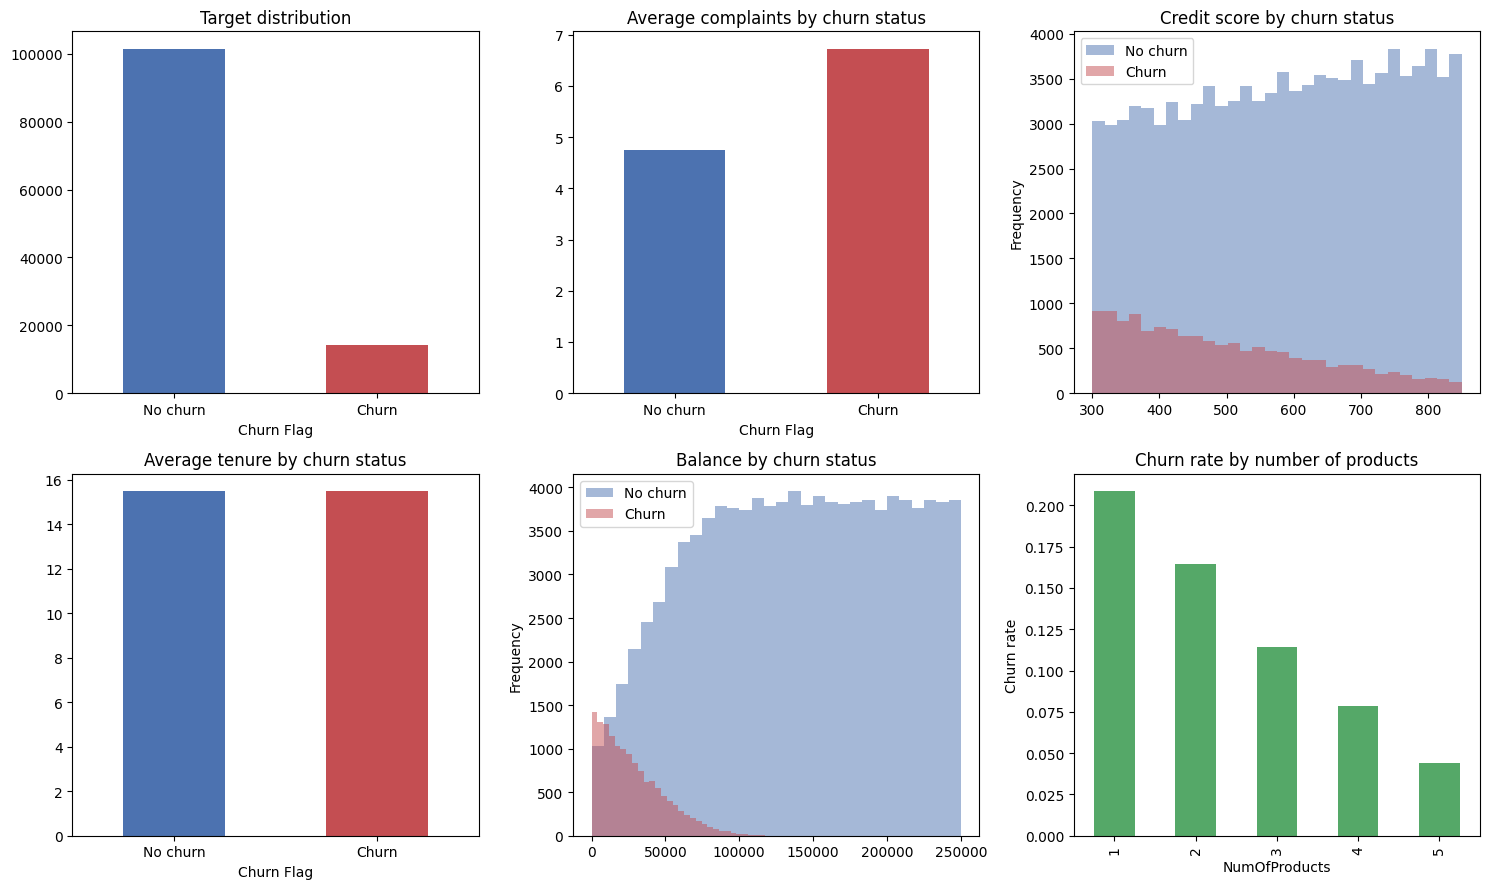

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

df['Churn Flag'].value_counts().sort_index().plot(kind='bar', ax=axes[0,0], color=['#4C72B0','#C44E52'])
axes[0,0].set_title('Target distribution')
axes[0,0].set_xticklabels(['No churn', 'Churn'], rotation=0)

df.groupby('Churn Flag')['NumComplaints'].mean().plot(kind='bar', ax=axes[0,1], color=['#4C72B0','#C44E52'])
axes[0,1].set_title('Average complaints by churn status')
axes[0,1].set_xticklabels(['No churn', 'Churn'], rotation=0)

for flag, colour, label in [(0, '#4C72B0', 'No churn'), (1, '#C44E52', 'Churn')]:
    df[df['Churn Flag']==flag]['Credit Score'].plot(kind='hist', bins=30, alpha=0.5, ax=axes[0,2], color=colour, label=label)
axes[0,2].set_title('Credit score by churn status'); axes[0,2].legend()

df.groupby('Churn Flag')['Customer Tenure'].mean().plot(kind='bar', ax=axes[1,0], color=['#4C72B0','#C44E52'])
axes[1,0].set_title('Average tenure by churn status')
axes[1,0].set_xticklabels(['No churn', 'Churn'], rotation=0)

for flag, colour, label in [(0, '#4C72B0', 'No churn'), (1, '#C44E52', 'Churn')]:
    df[df['Churn Flag']==flag]['Balance'].plot(kind='hist', bins=30, alpha=0.5, ax=axes[1,1], color=colour, label=label)
axes[1,1].set_title('Balance by churn status'); axes[1,1].legend()

df.groupby('NumOfProducts')['Churn Flag'].mean().plot(kind='bar', ax=axes[1,2], color='#55A868')
axes[1,2].set_title('Churn rate by number of products')
axes[1,2].set_ylabel('Churn rate')

plt.tight_layout()
plt.show()

### 3.2 Relationship between numeric features and churn

Balance                 -0.500
Credit Score            -0.183
NumOfProducts           -0.179
Outstanding Loans       -0.001
Customer Tenure          0.000
Income                   0.002
Credit History Length    0.003
Number of Dependents     0.003
NumComplaints            0.205
Name: Churn Flag, dtype: float64


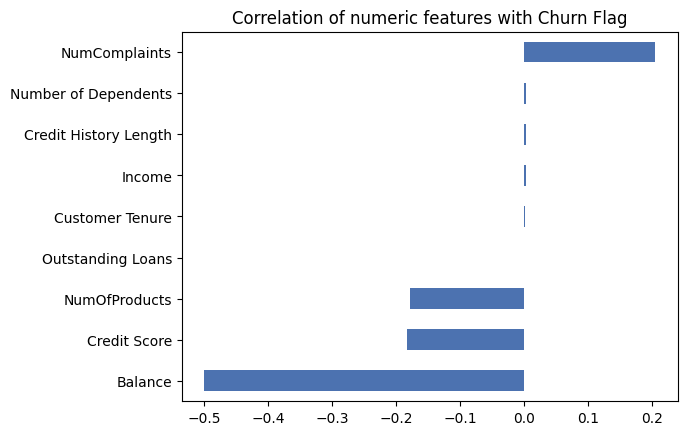

In [8]:
numeric_cols = ['Number of Dependents', 'Income', 'Customer Tenure', 'Credit Score',
                'Credit History Length', 'Outstanding Loans', 'Balance',
                'NumOfProducts', 'NumComplaints']
corr = df[numeric_cols + ['Churn Flag']].corr()['Churn Flag'].drop('Churn Flag').sort_values()
print(corr.round(3))
corr.plot(kind='barh', color='#4C72B0')
plt.title('Correlation of numeric features with Churn Flag')
plt.show()

**Findings:** Balance has by far the strongest relationship with churn (correlation about -0.50), so churned customers tend to hold much lower balances. Number of complaints is the strongest positive signal (about +0.20). Number of products and credit score both show a moderate negative relationship (about -0.18), and churn rate falls steadily as customers hold more products. Tenure, income, dependents, credit history length and outstanding loans have almost no relationship with churn, so I do not expect them to matter much in a model.

### 3.3 Outliers and erroneous values

In [9]:
print(df[['Credit Score', 'Balance', 'Income', 'Age']].describe().round(1) if 'Age' in df.columns
      else df[['Credit Score', 'Balance', 'Income']].describe().round(1))
print()
print('Negative balances:', (df['Balance'] < 0).sum())
print('Negative incomes:', (df['Income'] < 0).sum())
print('Credit scores outside 300 to 850:', ((df['Credit Score'] < 300) | (df['Credit Score'] > 850)).sum())

       Credit Score   Balance    Income
count      115640.0  115640.0  115640.0
mean          574.3  124639.2   52641.4
std           159.1   72210.5   27429.8
min           300.0       1.1    5001.0
25%           436.0   61991.9   28857.1
50%           574.0  124505.9   52658.1
75%           712.0  187122.9   76364.2
max           850.0  249998.9   99999.5

Negative balances: 0
Negative incomes: 0
Credit scores outside 300 to 850: 0


**Finding:** Credit scores sit inside the standard 300 to 850 range and there are no negative balances or incomes. Nothing needed cleaning, which fits with the data being synthetic. Missingness was already shown to be zero in Task 2.

### 3.4 Baseline and evaluation plan

**Evaluation metrics:** precision, recall and F1 on the churn class, a confusion matrix, and ROC-AUC. Accuracy is reported only to show why it is misleading.

**Split:** a stratified 80/20 train and test split so both sets keep the 12% churn rate. There is no time ordering in the data, so split order does not create leakage.

**Baseline 1:** majority-class prediction (always predict no churn).

**Baseline 2:** a simple logistic regression using Balance, NumComplaints, NumOfProducts and Credit Score, since these showed the clearest relationships with churn. `Churn Reason` and all sensitive attributes are excluded.

In [10]:
features = FEATURES
X = df[features]
y = df[TARGET]

X_train, X_test, y_train, y_test = split_data(X, y)

print('Train churn rate:', round(y_train.mean(), 4))
print('Test churn rate: ', round(y_test.mean(), 4))

Train churn rate: 0.1219
Test churn rate:  0.1219


**Save the processed data.** The modelling table (chosen features plus the target, with `Churn Reason` and all sensitive columns removed) is saved to `data/processed/`. The raw file in `data/raw/` is never changed.

In [11]:
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
df[features + [TARGET]].to_csv(PROCESSED_PATH, index=False)
print('Saved:', PROCESSED_PATH.name, '| rows:', len(df))

Saved: churn_model_ready.csv | rows: 115640


**Baseline 1: majority class**

In [12]:
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
pred_dummy = dummy.predict(X_test)
print(classification_report(y_test, pred_dummy, zero_division=0))
print('ROC-AUC:', round(roc_auc_score(y_test, dummy.predict_proba(X_test)[:, 1]), 3))

              precision    recall  f1-score   support

           0       0.88      1.00      0.94     20309
           1       0.00      0.00      0.00      2819

    accuracy                           0.88     23128
   macro avg       0.44      0.50      0.47     23128
weighted avg       0.77      0.88      0.82     23128



ROC-AUC: 0.5


The majority-class baseline gets about 88% accuracy but 0% recall on churn, because it never predicts churn. This confirms why accuracy is not a useful measure on its own.

**Baseline 2: logistic regression**

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     20309
           1       1.00      1.00      1.00      2819

    accuracy                           1.00     23128
   macro avg       1.00      1.00      1.00     23128
weighted avg       1.00      1.00      1.00     23128

ROC-AUC: 1.0


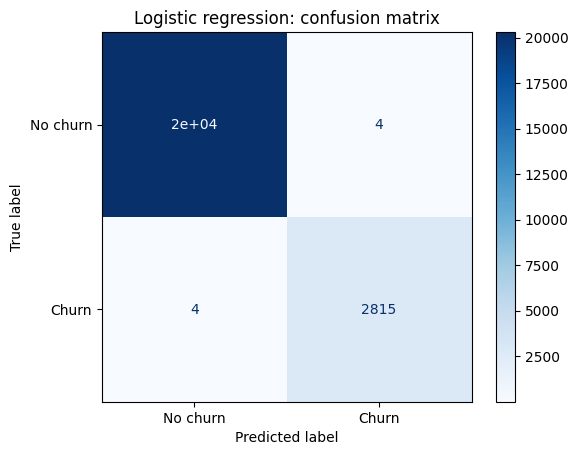

In [13]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
logreg.fit(X_train, y_train)
pred_lr = logreg.predict(X_test)
proba_lr = logreg.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred_lr, zero_division=0))
print('ROC-AUC:', round(roc_auc_score(y_test, proba_lr), 3))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_lr),
                       display_labels=['No churn', 'Churn']).plot(cmap='Blues')
plt.title('Logistic regression: confusion matrix')
plt.show()

**Threshold check.** The default 0.5 threshold is not always best when churn is rare. Because a missed churner costs more than an unnecessary retention offer, I check how recall and precision trade off as I lower the threshold.

In [14]:
threshold_table(y_test, proba_lr)

,threshold,recall,precision
0,0.50,0.999,0.999
1,0.40,1.000,0.977
2,0.30,1.000,0.949
3,0.20,1.000,0.916
4,0.15,1.000,0.899


**Unexpected result: near-perfect performance.** The logistic regression reaches precision and recall of about 1.00 and a ROC-AUC of 1.0. That is far better than anything I would expect on real churn data, so I checked whether it is genuine or a warning sign before trusting it.

In [15]:
from sklearn.model_selection import cross_val_score
import itertools

cv_auc = cross_val_score(logreg, X, y, cv=5, scoring='roc_auc')
print('5-fold cross-validated ROC-AUC:', cv_auc.round(4))

logreg.fit(X, y)
print()
print('Standardised coefficients:')
print(dict(zip(features, logreg[-1].coef_[0].round(2))))

print()
print('ROC-AUC using single features and pairs of features (test set):')
for r in [1, 2]:
    for combo in itertools.combinations(features, r):
        Xtr, Xte, ytr, yte = split_data(df[list(combo)], y)
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
        print(' ', combo, round(roc_auc_score(yte, m.predict_proba(Xte)[:, 1]), 3))

5-fold cross-validated ROC-AUC: [1. 1. 1. 1. 1.]

Standardised coefficients:
{'Balance': np.float64(-32.4), 'NumComplaints': np.float64(9.53), 'NumOfProducts': np.float64(-8.47), 'Credit Score': np.float64(-8.44)}

ROC-AUC using single features and pairs of features (test set):
  ('Balance',) 0.944


  ('NumComplaints',) 0.685
  ('NumOfProducts',) 0.659
  ('Credit Score',) 0.656


  ('Balance', 'NumComplaints') 0.968
  ('Balance', 'NumOfProducts') 0.964
  ('Balance', 'Credit Score') 0.961


  ('NumComplaints', 'NumOfProducts') 0.744
  ('NumComplaints', 'Credit Score') 0.743
  ('NumOfProducts', 'Credit Score') 0.723


**Interpretation.** No single feature does the job (Balance alone gives an AUC of about 0.94, the others about 0.66 to 0.69), but the four together separate the classes essentially perfectly, in every cross-validation fold, with very large coefficients. This is not what real customer behaviour looks like. It strongly suggests the churn flag in this dataset was generated from a near-deterministic combination of these four features. It is not data leakage in the usual sense, because none of these columns is recorded after the customer leaves, but it means the model is recovering the rule that produced the labels and not learning human behaviour. Any score I report on this dataset therefore says very little about how the approach would perform on a real Botswana bank.

### 3.5 Summary of the evaluation plan

| Item | Decision |
|---|---|
| Baseline | Majority-class prediction, then a simple logistic regression on four features |
| Metrics | Precision, recall and F1 on the churn class, confusion matrix, ROC-AUC |
| Split | Stratified 80/20, random_state 42 (set once in src/churn_utils.py) |
| What better looks like | Clearly higher recall on churners than the majority baseline (which has 0%), with precision high enough that retention outreach is not wasted. I originally planned a recall target of roughly 60 to 70%, but the logistic baseline already reaches about 100% on this dataset, so the target is not informative here. On real data I would expect a much lower ceiling and would set the target then. |
| Excluded features | Churn Reason (leakage) and sensitive attributes (gender, marital status, income, education, occupation, address) |

The near-perfect baseline, together with the absence of any relationship between churn and tenure, income or dependents, tells me this dataset does not capture realistic customer behaviour. I carry that into my Task 4 justification.